<p align="center">
    <img src="https://github.com/GeostatsGuy/GeostatsPy/blob/master/TCG_color_logo.png?raw=true" width="220" height="240" />
</p>

## Can Dimensional Analysis Make Machine Learning Models Extrapolate?
### Input Representation vs Model Choice under Distribution Shift

#### Nakul Sanadhya
#### Hildebrand Department of Petroleum and Geosystems Engineering, Cockrell School of Engineering, The University of Texas at Austin

### Subsurface Machine Learning Course, The University of Texas at Austin
#### Hildebrand Department of Petroleum and Geosystems Engineering, Cockrell School of Engineering
#### Department of Geological Sciences, Jackson School of Geosciences

_____________________

Workflow supervision and review by:

#### Instructor: Prof. Michael Pyrcz, Ph.D., P.Eng., Professor, The University of Texas at Austin
[Twitter](https://twitter.com/geostatsguy) | [GitHub](https://github.com/GeostatsGuy) | [Website](http://michaelpyrcz.com) | [GoogleScholar](https://scholar.google.com/citations?user=QVZ20eQAAAAJ&hl=en&oi=ao) | [Applied Machine Learning in Python e-book](https://geostatsguy.github.io/MachineLearningDemos_Book/) | [LinkedIn](https://www.linkedin.com/in/michael-pyrcz-61a648a1)

#### Course TA: Alexander Ifenaike, Graduate Student, The University of Texas at Austin

### Executive Summary

Machine learning proxies of physical simulators are trained on a limited range of inputs but are often used outside it, and it is not obvious whether the choice of model or the choice of input representation controls the damage. I compared raw, log-transformed and dimensionless (physics-based) representations of 2,900 simulations of layered 1D consolidation, each with linear regression, a random forest and a neural network tuned by grouped cross-validation, on in-range test data and on two shifts: larger absolute scales, and a fluid-solid coupling beyond its training range. The representation mattered more than the model: dimensionless inputs turned the scale shift back into interpolation (best P95 worst error 3.2%, against 3.6% in range and 52-362% for raw and log inputs) and limited the coupling shift to 6-16%, while random-row cross-validation overstated accuracy 6-fold. Nondimensionalise inputs and target before fitting, check where new cases fall in the dimensionless input space, and validate with folds grouped by simulation.

### Import Packages

In [1]:
import sys                                    # Python version
import time                                   # run time
import warnings                               # silence MLP iteration warnings
import numpy as np                            # arrays, percentiles
import pandas as pd                           # CSV files, results table
import matplotlib as mpl                      # version
import matplotlib.pyplot as plt               # figures
import sklearn                                # version
from joblib import parallel_config            # threads per CV worker
from matplotlib.patches import Rectangle      # schematic, training box
from matplotlib.ticker import NullFormatter   # plain log-axis ticks
from sklearn.compose import TransformedTargetRegressor  # scaled target
from sklearn.ensemble import RandomForestRegressor      # tree ensemble
from sklearn.exceptions import ConvergenceWarning       # warning silenced
from sklearn.inspection import permutation_importance   # importance
from sklearn.linear_model import LinearRegression       # linear model
from sklearn.model_selection import GroupKFold, KFold   # CV folds
from sklearn.model_selection import cross_val_predict   # out-of-fold
from sklearn.neural_network import MLPRegressor         # neural network
from sklearn.pipeline import make_pipeline              # scaler + model
from sklearn.preprocessing import StandardScaler        # standardize
from threadpoolctl import threadpool_limits             # cap threads
%config InlineBackend.figure_formats = ['svg']
print(f"Python {sys.version.split()[0]}, numpy {np.__version__}, "
      f"pandas {pd.__version__}, scikit-learn {sklearn.__version__}, "
      f"matplotlib {mpl.__version__}")

Python 3.12.7, numpy 1.26.4, pandas 2.2.2, scikit-learn 1.7.1, matplotlib 3.9.2


### Functions

The following functions will be used in the workflow.

* `physics`: closed-form undrained and drained settlements and series-averaged properties of each column
* `represent`: one of the three input representations, one row per (simulation, time)

In [2]:
MU, N_T, SEED = 1e-3, 41, 0         # water viscosity [Pa s], times, seed
N_JOBS, CV_JOBS = 8, 3              # threads; CV folds run in parallel
TIMES = [f"t_{i:02d}" for i in range(N_T)]
SETTLE = [f"s_{i:02d}" for i in range(N_T)]
INPUTS = ["H_m", "sigma0_Pa", "M_Pa", "alpha", "k1_m2", "k2_m2", "k3_m2",
          "Mc1_Pa", "Mc2_Pa", "Mc3_Pa"]
KINDS = ["raw", "log", "dimensionless"]
DIM_NAMES = ["log Tv", "log cv1/cv", "log cv2/cv", "log cv3/cv",
             "log Mc1/Mc", "log Mc2/Mc", "log Mc3/Mc", "α", "log κ"]

def physics(df):
    """Closed-form limits and series-averaged properties (3 equal layers)."""
    H, sig, M, a = (df[c].to_numpy() for c in INPUTS[:4])
    k, Mc = df[INPUTS[4:7]].to_numpy(), df[INPUTS[7:]].to_numpy()
    Mc_eff, k_eff = 3 / (1 / Mc).sum(1), 3 / (1 / k).sum(1)
    cv = k / MU / (1 / M[:, None] + a[:, None] ** 2 / Mc)     # [m2/s]
    cv_eff = k_eff / MU / (1 / M + a ** 2 / Mc_eff)
    Mu = Mc + a[:, None] ** 2 * M[:, None]                   # undrained
    return dict(H=H, alpha=a, Mc=Mc, Mc_eff=Mc_eff, cv=cv, cv_eff=cv_eff,
                s0=sig * H / 3 * (1 / Mu).sum(1),            # [m]
                s_inf=sig * H / 3 * (1 / Mc).sum(1),         # [m]
                kappa=a ** 2 * M / Mc_eff)

def represent(df, kind):
    """X and y, one row per (simulation, time), and the map y -> s [m]."""
    p, t, s = physics(df), df[TIMES].to_numpy(), df[SETTLE].to_numpy()
    rep = lambda v: np.repeat(np.asarray(v), N_T)    # value on every time
    if kind == "raw":
        X = np.column_stack([rep(df[c]) for c in INPUTS] + [t.ravel()])
        return X, s.ravel(), lambda y: y
    if kind == "log":
        X = np.column_stack(
            [rep(df[c] if c == "alpha" else np.log10(df[c])) for c in INPUTS]
            + [np.log10(t).ravel()])
        return X, np.log10(s).ravel(), lambda y: 10 ** y
    Tv = t * p["cv_eff"][:, None] / p["H"][:, None] ** 2     # clock [-]
    X = np.column_stack(
        [np.log10(Tv).ravel()]
        + [rep(np.log10(p["cv"][:, j] / p["cv_eff"])) for j in range(3)]
        + [rep(np.log10(p["Mc"][:, j] / p["Mc_eff"])) for j in range(3)]
        + [rep(p["alpha"]), rep(np.log10(p["kappa"]))])
    s0, s_inf = rep(p["s0"]), rep(p["s_inf"])
    return X, (s.ravel() - s0) / (s_inf - s0), lambda y: s0 + y * (s_inf - s0)

* `worst_error`, `scores`: the metric and the physical checks (defined in Step 3)
* `make_model`, `cv_predict`: the three models and their out-of-fold predictions

In [3]:
def worst_error(df, s_pred):
    """Worst error over time per run: / (s_inf - s0) and / s_inf."""
    p, s = physics(df), df[SETTLE].to_numpy()
    worst = np.abs(s_pred.reshape(s.shape) - s).max(1)
    return worst / (p["s_inf"] - p["s0"]), worst / p["s_inf"]

def scores(df, s_pred):
    """P95 over runs of the worst error [%]; % of runs failing a check."""
    p, sp = physics(df), s_pred.reshape(-1, N_T)
    primary, secondary = worst_error(df, s_pred)
    band = (p["s_inf"] - p["s0"])[:, None]
    falls = (np.diff(sp, axis=1) < -1e-3 * band).any(1)    # must not fall
    outside = ((sp < p["s0"][:, None] - 0.01 * band)
               | (sp > p["s_inf"][:, None] + 0.01 * band)).any(1)
    return {"P95": 100 * np.percentile(primary, 95),
            "P95 of s_inf": 100 * np.percentile(secondary, 95),
            "non-monotone": 100 * falls.mean(),
            "out of bounds": 100 * outside.mean()}

GRIDS = {"linear": [{}],
         "random forest": [{"min_samples_leaf": n} for n in (1, 5)],
         "MLP": [{"alpha": a, "tol": tol}
                 for a in (1e-4, 1e-2) for tol in (1e-4, 1e-5)]}

def make_model(name, n_jobs=N_JOBS, **hp):
    """Standardized target; standardized inputs for linear model and MLP."""
    if name == "linear":
        est = make_pipeline(StandardScaler(), LinearRegression())
    elif name == "random forest":
        est = RandomForestRegressor(n_estimators=100, max_features=0.6,
                                    n_jobs=n_jobs, random_state=SEED, **hp)
    else:
        est = make_pipeline(StandardScaler(), MLPRegressor(
            hidden_layer_sizes=(64, 64), max_iter=500, early_stopping=False,
            random_state=SEED, **hp))
    return TransformedTargetRegressor(est, transformer=StandardScaler())

def cv_predict(name, hp, df, kind, cv):
    """Out-of-fold settlement [m]; 3 folds in parallel, 2 threads each."""
    X, y, to_s = represent(df, kind)
    groups = np.repeat(np.arange(len(df)), N_T)
    groups = groups if isinstance(cv, GroupKFold) else None
    with parallel_config(backend="loky", inner_max_num_threads=2):
        y_cv = cross_val_predict(make_model(name, n_jobs=2, **hp), X, y,
                                 groups=groups, cv=cv, n_jobs=CV_JOBS)
    return to_s(y_cv)

threadpool_limits(N_JOBS)                   # at most 8 threads in total
warnings.filterwarnings("ignore", category=ConvergenceWarning)

* one design system for every figure: colour = input representation (Okabe-Ito, colour-blind safe), marker and line style = model, panel = data split, grey band = training range

In [4]:
COLOR = {"raw": "#0072B2", "log": "#E69F00", "dimensionless": "#009E73"}
MODEL = {"linear": dict(marker="s", ls=":"),
         "random forest": dict(marker="^", ls="--"),
         "MLP": dict(marker="o", ls="-")}
BAND = dict(color="0.9", lw=0, zorder=0)               # training range
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 8.5, "axes.titlesize": 9,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "0.35", "xtick.color": "0.35", "ytick.color": "0.35",
    "axes.grid": True, "grid.color": "0.92", "grid.linewidth": 0.6,
    "lines.linewidth": 1.4, "svg.fonttype": "path", "svg.hashsalt": "pge383",
    "savefig.dpi": 200})

def note(ax, x, y, text, box=False, **kw):
    """Direct label on a plot, optionally on a white box."""
    kw = dict(fontsize=7.5, ha="center", va="center") | kw
    if box:
        kw["bbox"] = dict(fc="white", ec="none", alpha=0.85, pad=1.2)
    ax.text(x, y, text, **kw)

def plain_log(axis, ticks, labels=None):
    """Log axis with chosen ticks and plain labels."""
    axis.set_ticks(ticks, labels or [f"{t:g}" for t in ticks])
    axis.set_minor_formatter(NullFormatter())

### Load Data

2,900 simulations of 1D consolidation of a three-layer column, from a layered finite-volume solver extended from the reference solver in [poroConsolidationFoam](https://github.com/nakulsanadhya/poroConsolidationFoam) (verified against the exact Terzaghi solution):
* at t = 0 a load σ0 is applied on top; water drains through the top and the column settles from the undrained settlement s0 to the drained settlement s∞
* one row per simulation: 10 inputs, then 41 times `t_00`-`t_40` [s] and settlements `s_00`-`s_40` [m]
* inputs: thickness **H** [m], load **σ0** [Pa], Biot modulus **M** [Pa] (fluid and pore compressibility), Biot coefficient **α** [-], and per layer the permeability **k1-k3** [m²] and drained constrained modulus **Mc1-Mc3** [Pa]
* splits: **train** (2000) and **test** (300) share the input ranges; **ood_scale** (300) has thicker columns, larger loads and 10x higher permeability; **ood_coupling** (300) keeps every input in range except M, set so that the coupling group κ = α²M/Mc,eff lies 1-10x below (150) or above (150) its training range
* the high side needs M up to 4e12 Pa, far beyond water-saturated rock: a pure extrapolation test, not a realistic rock

In [5]:
LOCAL = False                       # SWITCH: True reads a local data/
URL = ("https://raw.githubusercontent.com/nakulsanadhya/"
       "dimensionless-features-ml-extrapolation/main/data/")
data = {s: pd.read_csv(f"{'data/' if LOCAL else URL}{s}.csv")
        for s in ["train", "test", "ood_scale", "ood_coupling"]}
K_MIN = physics(data["train"])["kappa"].min()   # training range of κ
K_MAX = physics(data["train"])["kappa"].max()
kappa = physics(data["ood_coupling"])["kappa"]
data["κ below"] = data["ood_coupling"][kappa < K_MIN].reset_index(drop=True)
data["κ above"] = data["ood_coupling"][kappa > K_MAX].reset_index(drop=True)
EVAL = ["test", "ood_scale", "κ below", "κ above"]

### Workflow

1. The problem and the shifts
2. Three representations of the same data
3. Validation design: grouped cross-validation and leakage
4. Hyperparameter tuning by grouped cross-validation
5. Headline: representation x model x split
6. Why: how each model extrapolates
7. Which inputs does the best model use?

### 1. The Problem and the Shifts

**Extrapolation** is prediction outside the region of input space covered by the training data; there the prediction is set by the model's built-in assumptions, not by data ([e-book: Decision Tree](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_decision_tree.html), [Model Checking](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_model_checking.html)).

**Question:** what must a model learn, and how far outside the training data does each test set sit?

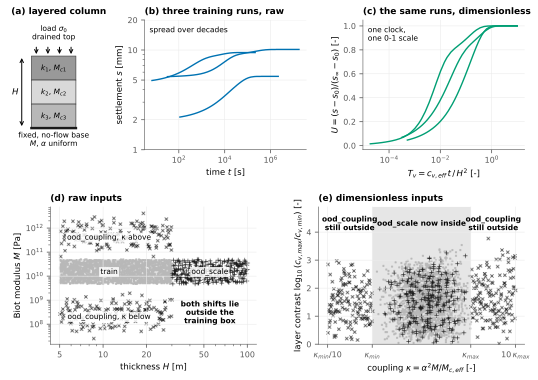

In [6]:
tr, ptr = data["train"], physics(data["train"])
Tc = ptr["H"] ** 2 / ptr["cv_eff"]                    # consolidation time
runs = [int(np.abs(Tc - np.quantile(Tc, q)).argmin()) for q in (.1, .5, .9)]
fig = plt.figure(figsize=(7.5, 5.3))
top = fig.add_gridspec(1, 3, width_ratios=[1, 2, 2], left=0.01, right=0.97,
                       top=0.94, bottom=0.6, wspace=0.42)
low = fig.add_gridspec(1, 2, left=0.09, right=0.97, top=0.45, bottom=0.09,
                       wspace=0.3)
ax = [fig.add_subplot(g) for g in (top[0], top[1], top[2], low[0], low[1])]

a = ax[0]; a.set_axis_off(); a.set(xlim=(0, 1), ylim=(-0.3, 1.5))
for j, grey in enumerate(("0.6", "0.85", "0.72")):       # layers 1-3
    y0 = 1 - (j + 1) / 3
    a.add_patch(Rectangle((0.3, y0), 0.55, 1 / 3, fc=grey, ec="0.2", lw=.6))
    note(a, 0.575, y0 + 1 / 6, f"$k_{j+1}$, $M_{{c{j+1}}}$")
for x in np.linspace(0.36, 0.79, 4):
    a.annotate("", (x, 1.0), (x, 1.15), arrowprops=dict(arrowstyle="->"))
note(a, 0.575, 1.32, "load $\\sigma_0$\ndrained top")
a.plot([0.3, 0.85], [0, 0], color="0.1", lw=2.5)
note(a, 0.575, -0.16, "fixed, no-flow base\n$M$, $\\alpha$ uniform")
a.annotate("", (0.18, 0), (0.18, 1), arrowprops=dict(arrowstyle="<->"))
note(a, 0.1, 0.5, "$H$", fontsize=8.5)
a.set_title("(a) layered column", x=0.05)

X, U, _ = represent(tr.loc[runs], "dimensionless")
for i, tv, u in zip(runs, 10 ** X[:, 0].reshape(3, N_T), U.reshape(3, N_T)):
    ax[1].loglog(tr.loc[i, TIMES], 1e3 * tr.loc[i, SETTLE], c=COLOR["raw"])
    ax[2].semilogx(tv, u, color=COLOR["dimensionless"])
plain_log(ax[1].yaxis, [1, 2, 5, 10, 20])
ax[1].set(xlabel="time $t$ [s]", ylabel="settlement $s$ [mm]",
          title="(b) three training runs, raw")
ax[2].set(xlabel="$T_v = c_{v,eff}\\,t\\,/\\,H^2$ [-]",
          ylabel="$U = (s - s_0)/(s_\\infty - s_0)$ [-]",
          title="(c) the same runs, dimensionless")
note(ax[1], 0.03, 0.95, "spread over decades", ha="left", va="top",
     transform=ax[1].transAxes)
note(ax[2], 0.03, 0.95, "one clock,\none 0-1 scale", ha="left", va="top",
     transform=ax[2].transAxes)

look = {"train": dict(color="0.72", marker=".", s=6),
        "ood_scale": dict(color="0.1", marker="+", s=14, lw=0.6),
        "ood_coupling": dict(color="0.1", marker="x", s=10, lw=0.6)}
H, M = tr["H_m"], tr["M_Pa"]
ax[3].add_patch(Rectangle((H.min(), M.min()), H.max() - H.min(),
                          M.max() - M.min(), **BAND))
ax[4].axvspan(K_MIN, K_MAX, **BAND)
for split, kw in look.items():
    df, p = data[split], physics(data[split])
    contrast = np.log10(p["cv"].max(1) / p["cv"].min(1))
    ax[3].scatter(df["H_m"], df["M_Pa"], rasterized=True, **kw)
    ax[4].scatter(p["kappa"], contrast, rasterized=True, **kw)
ax[3].set(xscale="log", yscale="log", xlabel="thickness $H$ [m]",
          ylabel="Biot modulus $M$ [Pa]", title="(d) raw inputs")
plain_log(ax[3].xaxis, [5, 10, 20, 50, 100])
for x, y, s in ((11, 4e11, "ood_coupling, κ above"), (55, 1.5e10, "ood_scale"),
                (11, 2e8, "ood_coupling, κ below"), (11, 1.5e10, "train")):
    note(ax[3], x, y, s, box=True)
note(ax[3], 55, 3e8, "both shifts lie\noutside the\ntraining box",
     fontweight="bold")
ax[4].set_xscale("log")
plain_log(ax[4].xaxis, [K_MIN / 10, K_MIN, K_MAX, 10 * K_MAX],
          ["$\\kappa_{min}/10$", "$\\kappa_{min}$", "$\\kappa_{max}$",
           "$10\\,\\kappa_{max}$"])
ax[4].minorticks_off()
ax[4].set(ylim=(0, 4.9), title="(e) dimensionless inputs",
          xlabel="coupling $\\kappa = \\alpha^2 M / M_{c,eff}$ [-]",
          ylabel="layer contrast $\\log_{10}(c_{v,max}/c_{v,min})$ [-]")
note(ax[4], np.sqrt(K_MIN * K_MAX), 4.3, "ood_scale now inside",
     fontweight="bold")
for x in (K_MIN / 3.2, K_MAX * 3.2):
    note(ax[4], x, 4.3, "ood_coupling\nstill outside", fontweight="bold")
plt.show()

* in raw form (b) the histories spread over decades of time and settlement; in dimensionless form (c) they share one clock and one 0-1 scale, and the remaining spread is the layering, which is what a model must learn
* in raw inputs (d) both shifts are extrapolation: ood_scale in thickness (and load, permeability), ood_coupling in the Biot modulus
* in dimensionless inputs (e) ood_scale falls inside the training cloud, the same dimensionless problem at a larger scale; only ood_coupling stays outside, in κ

### 2. Three Representations of the Same Data

**Feature transformation** changes how the same information is presented to a model ([e-book: Feature Transformations](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_feature_transformations.html)); here inputs and target change together:

| representation | inputs | target | back to settlement |
|---|---|---|---|
| raw | H, σ0, M, α, k1-3, Mc1-3, t (11) | s [m] | identity |
| log | log10 of each (α linear), log10 t (11) | log10 s | 10^y |
| dimensionless | log Tv, log cv,j/cv,eff, log Mc,j/Mc,eff, α, log κ (9) | U = (s − s0)/(s∞ − s0) | s0 + U (s∞ − s0) |

* dimensional analysis (Buckingham π): the equations depend only on a few dimensionless groups, so H and σ0 drop out exactly (σ0 by linearity, H into the clock Tv = cv,eff t/H²)
* the dimensionless representation also uses known physics, the closed-form limits s0 and s∞ (layers in series); this is part of what is tested
* trees split on one input at a time and are unchanged by monotone transforms of an input, so for the random forest raw and log differ only in the target

### 3. Validation Design: Grouped Cross-Validation and Leakage

**Metric:** for each simulation the worst error over its 41 times, divided by s∞ − s0, the delayed part of the settlement that the model must learn; the score is the 95th percentile (P95) over simulations.
* worst case rather than average, because a proxy is trusted run by run; error relative to the total settlement s∞ is a secondary column
* harsh where s∞ − s0 is small: below the κ range it is only 1-11% of s∞, for every model
* two physical checks per predicted history: settlement must not decrease, and must stay between s0 and s∞ (1% tolerance)

**Data leakage:** information from the validation data reaches the training data ([e-book: Training and Tuning](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_training_tuning.html)). Rows of one simulation (neighbouring times) are nearly identical, so random-row K-fold puts near-copies of each validation row into training; grouped K-fold keeps each simulation in one fold ([glossary: groups](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_glossary_a_c.html)). The MLP's built-in `early_stopping` also holds out random rows, so it is off.

**Question:** does random-row K-fold tell us how well a model predicts a new simulation? (random forest, raw inputs, default settings, 800 training simulations)

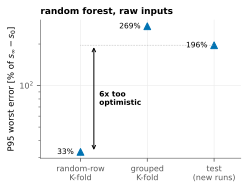

In [7]:
tune = data["train"].iloc[:800]                       # simulations for CV
folds = {"random-row\nK-fold": KFold(3, shuffle=True, random_state=SEED),
         "grouped\nK-fold": GroupKFold(3)}
leak = {k: scores(tune, cv_predict("random forest", {}, tune, "raw", cv))
        ["P95"] for k, cv in folds.items()}
X, y, _ = represent(tune, "raw")
X_test, _, to_s = represent(data["test"], "raw")
s_test = to_s(make_model("random forest").fit(X, y).predict(X_test))
leak["test\n(new runs)"] = scores(data["test"], s_test)["P95"]

fig, ax = plt.subplots(figsize=(3.6, 2.5))
v = list(leak.values())
ax.scatter(range(3), v, color=COLOR["raw"], marker="^", s=45, zorder=2)
for i, val in enumerate(v):
    note(ax, i - 0.1, val, f"{val:.0f}%", ha="right")
ax.hlines(v[2], 0, 2, color="0.6", lw=0.6, ls=":")
ax.annotate("", (0.2, v[0]), (0.2, v[2]), arrowprops=dict(arrowstyle="<->"))
note(ax, 0.28, np.sqrt(v[0] * v[2]), f"{v[2] / v[0]:.0f}x too\noptimistic",
     ha="left", fontweight="bold")
ax.set_yscale("log"); ax.set_xlim(-0.6, 2.4)
ax.set_xticks(range(3), list(leak))
ax.set(ylabel="P95 worst error [% of $s_\\infty - s_0$]",
       title="random forest, raw inputs")
plt.show()

* random-row K-fold reports 33% against a true test error of 196%: 6x too optimistic, because the forest interpolates between neighbouring times of a simulation that the validation fold still contains
* grouped K-fold is somewhat pessimistic (269% vs 196%), because each fold trains on only two thirds of the 800 tuning simulations; it is the estimate used from here on

### 4. Hyperparameter Tuning by Grouped Cross-Validation

**Hyperparameters** are chosen on validation folds, never on test data ([e-book: Training and Tuning](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_training_tuning.html)):
* 3-fold grouped K-fold on 800 training simulations, then the chosen setting is refitted on all 2000; grids fixed before any result was seen: random forest (100 trees) min_samples_leaf ∈ {1, 5}; MLP (64, 64 ReLU units) L2 penalty α ∈ {1e-4, 1e-2} x stopping tolerance ∈ {1e-4, 1e-5}; linear regression has none
* selection uses the reported metric (P95 worst error) on out-of-fold predictions, not the mean squared error of each representation's own target: MSE of s, log s and U are on different scales and weight runs differently, so only the reported metric compares across representations
* the best model overall (lowest grouped-CV score) is used in Step 7; test and out-of-range scores play no part in any choice

**Question:** which setting does grouped CV choose for each of the 9 combinations? (listed in the Results table)

In [8]:
rows, fitted = [], {}
for kind in KINDS:
    X, y, _ = represent(data["train"], kind)
    for name, grid in GRIDS.items():
        cv = [scores(tune, cv_predict(name, hp, tune, kind, GroupKFold(3)))
              ["P95"] for hp in grid]
        hp = grid[int(np.argmin(cv))]
        rows.append({"representation": kind, "model": name, "CV": min(cv),
                     "chosen": " ".join(f"{k}={v:g}" for k, v in hp.items())
                     or "-"})
        fitted[kind, name] = make_model(name, **hp).fit(X, y)
tuning = pd.DataFrame(rows).set_index(["representation", "model"])
best = tuning["CV"].idxmin()                    # (representation, model)

### 5. Headline: Representation x Model x Split

**Question:** under distribution shift, which matters more, the input representation or the model? (all 9 combinations, refitted on 2000 simulations)

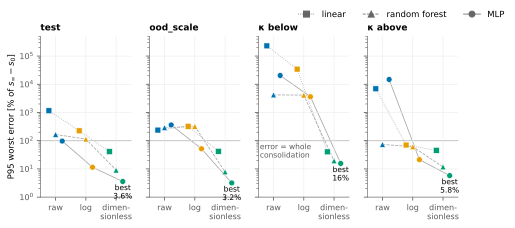

In [9]:
pred, res = {}, {}
for (kind, name), model in fitted.items():
    for split in EVAL:
        X, _, to_s = represent(data[split], kind)
        pred[kind, name, split] = p = to_s(model.predict(X))
        res[kind, name, split] = scores(data[split], p)

fig, axes = plt.subplots(1, 4, figsize=(7.5, 2.9), sharey=True)
shift = dict(zip(GRIDS, (-0.22, 0.0, 0.22)))
for ax, split in zip(axes, EVAL):
    ax.axhline(100, color="0.45", lw=0.7, zorder=1)
    for name in GRIDS:
        x = [i + shift[name] for i in range(3)]
        v = [res[k, name, split]["P95"] for k in KINDS]
        ax.plot(x, v, color="0.65", lw=0.8, ls=MODEL[name]["ls"], zorder=1)
        ax.scatter(x, v, c=[COLOR[k] for k in KINDS], s=34, zorder=2,
                   marker=MODEL[name]["marker"], edgecolors="white", lw=0.5)
    k, n = min(fitted, key=lambda kn: res[kn[0], kn[1], split]["P95"])
    v = res[k, n, split]["P95"]
    note(ax, KINDS.index(k) + shift[n], v / 2.4, f"best\n{v:.2g}%")
    ax.set_xticks(range(3), ["raw", "log", "dimen-\nsionless"])
    ax.set(xlim=(-0.5, 2.5), yscale="log", ylim=(1, 5e5), title=split)
axes[0].set_ylabel("P95 worst error [% of $s_\\infty - s_0$]")
note(axes[2], -0.45, 80, "error = whole\nconsolidation", ha="left",
     va="top", color="0.35")
handles = [plt.Line2D([], [], color="0.4", lw=0.8, **MODEL[n]) for n in GRIDS]
fig.legend(handles, list(GRIDS), loc="upper right", ncol=3, frameon=False,
           bbox_to_anchor=(1, 1.04))                 # model key, once
plt.show()

* in range (test) the representation already matters more than the model: the best raw model (MLP, 97%) is worse than the worst dimensionless model (linear, 41%)
* ood_scale: the dimensionless models score as in range (MLP 3.2% vs 3.6%), so the scale shift became interpolation; raw and log models fail (52-362%)
* ood_coupling: the dimensionless models stay best (MLP 16% below, 5.8% above the range); the metric amplifies the gap below the range, where the delayed settlement s∞ − s0 is only 1-11% of the total and dividing by it inflates raw and log errors, while above the range most settlement is delayed, so the same errors look smaller, which is why some raw and log models score better there than in range

### 6. Why: How Each Model Extrapolates

**Inductive bias** is what a model assumes where it has no data ([e-book: Linear Regression](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_linear_regression.html), [Decision Tree](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_decision_tree.html), [Ensemble Trees](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_ensemble_trees.html), [Artificial Neural Networks](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_ANN.html)):
* linear regression: one global plane, so it extrapolates linearly
* trees and forests: piecewise constant, so a prediction never leaves the range of the training targets
* ReLU neural network: piecewise linear, so it continues its last trend

**Question:** what does each model predict beyond the training data? (a, b) ood_scale, raw-input forest and MLP against the dimensionless forest; (c) ood_coupling, the CV-best model of each representation, against distance beyond the training limit of κ

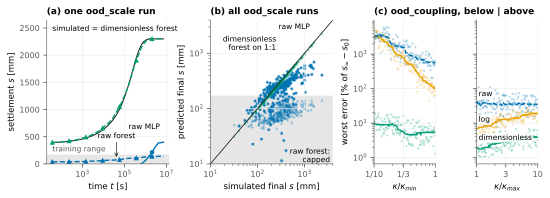

In [10]:
SHOW = {("raw", "random forest"): "raw forest", ("raw", "MLP"): "raw MLP",
        ("dimensionless", "random forest"): "dimensionless forest"}
sc = data["ood_scale"]; s_sc = 1e3 * sc[SETTLE].to_numpy()
s_top = 1e3 * tr[SETTLE].to_numpy().max()            # training maximum [mm]
case = int(s_sc[:, -1].argmax())                     # largest ood_scale run
fig = plt.figure(figsize=(7.5, 2.9))
gs = fig.add_gridspec(1, 4, width_ratios=[1.1, 1.1, 0.55, 0.55], left=0.08,
                      right=0.99, top=0.86, bottom=0.17, wspace=0.45)
a, b, c1 = (fig.add_subplot(gs[i]) for i in range(3))
c2 = fig.add_subplot(gs[3], sharey=c1)
t = sc.loc[case, TIMES].to_numpy(float)
a.axhspan(0, s_top, **BAND); b.axhspan(1, s_top, **BAND)
a.semilogx(t, s_sc[case], color="0.1", lw=1)
for (kind, name), label in SHOW.items():
    st = dict(color=COLOR[kind], marker=MODEL[name]["marker"])
    s_hat = 1e3 * pred[kind, name, "ood_scale"].reshape(-1, N_T)
    a.semilogx(t, s_hat[case], ls=MODEL[name]["ls"], ms=3.5, markevery=6,
               **st)
    if (kind, name) == ("raw", "MLP"):
        note(a, t[-1] / 1.5, s_hat[case, -1] + 280, label, ha="right")
    elif kind == "raw":                         # label in free space, arrow
        i = np.searchsorted(t, 3e4)
        a.annotate("", (t[i], s_hat[case, i] + 20), (t[i], s_top + 260),
                   arrowprops=dict(arrowstyle="->", lw=0.6))
        note(a, t[i], s_top + 340, label)
    b.scatter(s_sc[:, -1], s_hat[:, -1], s=8, lw=0, rasterized=True,
              alpha=0.9 if kind == "raw" and name == "MLP" else 0.45, **st)
a.set(ylim=(0, 1.15 * s_sc[case].max()), xlabel="time $t$ [s]",
      ylabel="settlement $s$ [mm]", title="(a) one ood_scale run")
note(a, t[0], 1.08 * s_sc[case].max(), "simulated = dimensionless forest",
     ha="left")
note(a, t[0], s_top + 30, "training range", ha="left", va="bottom",
     color="0.35")
lim = (10, 4000)
b.plot(lim, lim, color="0.1", lw=0.8)
b.set(xscale="log", yscale="log", xlim=lim, ylim=lim,
      xlabel="simulated final $s$ [mm]", ylabel="predicted final $s$ [mm]",
      title="(b) all ood_scale runs")
note(b, 250, 1500, "dimensionless\nforest on 1:1", ha="right")
note(b, 3500, 14, "raw forest:\ncapped", ha="right")
note(b, 1300, 3000, "raw MLP", ha="right")

best_of = tuning.reset_index().loc[
    tuning.reset_index().groupby("representation")["CV"].idxmin()]
for ax, split, limit in ((c1, "κ below", K_MIN), (c2, "κ above", K_MAX)):
    ratio = physics(data[split])["kappa"] / limit
    order = np.argsort(ratio)
    for kind, name in zip(best_of.representation, best_of.model):
        err = 100 * worst_error(data[split], pred[kind, name, split])[0]
        ax.scatter(ratio, err, s=4, lw=0, color=COLOR[kind], alpha=0.35,
                   rasterized=True)
        med = pd.Series(err[order]).rolling(31, center=True, min_periods=10)
        med = med.median().to_numpy()
        ax.plot(ratio[order], med, color=COLOR[kind], ls=MODEL[name]["ls"])
        if ax is c2:
            note(ax, 1.08, 1.9 * med[0], kind, ha="left", box=True)
    ax.set(xscale="log", yscale="log")
plain_log(c1.xaxis, [0.1, 0.3, 1], ["1/10", "1/3", "1"])
plain_log(c2.xaxis, [1, 3, 10])
c1.set(xlim=(0.1, 1), xlabel="$\\kappa/\\kappa_{min}$",
       ylabel="worst error [% of $s_\\infty - s_0$]")
c2.set(xlim=(1, 10), xlabel="$\\kappa/\\kappa_{max}$")
c2.tick_params(labelleft=False)
c1.set_title("(c) ood_coupling, below | above")
plt.show()

* (a, b) the raw-input forest never predicts more than 143 mm, inside the training range (at most 172 mm), while ood_scale runs settle up to 2.3 m; the raw MLP continues its trends and leaves the range in both directions
* the dimensionless forest follows the simulation: its target U always lies in [0, 1], so constant extrapolation costs nothing and the closed-form limits carry the scale
* (c) below the κ range raw and log errors grow with distance; dimensionless errors stay near 5-10% below and grow slowly above (median about 2% at the limit, 4% at 10x)

### 7. Which Inputs Does the Best Model Use?

**Permutation feature importance** shuffles one input and measures how much the score worsens; it works for any model ([e-book: Feature Ranking](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_feature_ranking.html); [scikit-learn user guide](https://scikit-learn.org/stable/modules/permutation_importance.html)). Here: test split (in range), primary metric, 5 repeats.

**Question:** does the best model (lowest grouped-CV score) rely on the physically expected inputs?

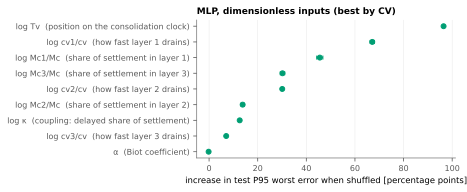

In [11]:
MEANING = {"log Tv": "position on the consolidation clock",
           "log κ": "coupling: delayed share of settlement",
           "α": "Biot coefficient",
           **{f"log cv{j}/cv": f"how fast layer {j} drains"
              for j in (1, 2, 3)},
           **{f"log Mc{j}/Mc": f"share of settlement in layer {j}"
              for j in (1, 2, 3)}}
kind, name = best
X, y, to_s = represent(data["test"], kind)
score = lambda est, X_, y_: -scores(data["test"], to_s(est.predict(X_)))["P95"]
imp = permutation_importance(fitted[best], X, y, scoring=score, n_repeats=5,
                             random_state=SEED)
order = np.argsort(imp.importances_mean)
names = DIM_NAMES if kind == "dimensionless" else [f"input {i}" for i in
                                                   range(X.shape[1])]
fig, ax = plt.subplots(figsize=(7.5, 2.5)); fig.subplots_adjust(left=0.42)
ax.errorbar(imp.importances_mean[order], range(len(order)), capsize=2,
            xerr=imp.importances_std[order], fmt=MODEL[name]["marker"],
            color=COLOR[kind], ms=5, elinewidth=0.8)
ax.set_yticks(range(len(order)), [f"{names[i]}  ({MEANING.get(names[i], '')})"
                                  for i in order])
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set(xlabel="increase in test P95 worst error when shuffled "
       "[percentage points]", title=f"{name}, {kind} inputs (best by CV)")
plt.show()

* the clock Tv dominates, followed by the drainage and stiffness ratios of layer 1, the drained top layer through which all water must leave: a physically sensible order
* κ matters little in range because most of its effect already sits in the closed-form limits s0 and s∞, which is why the coupling shift costs the dimensionless models little; importance in range says nothing about behaviour out of range

### Results

**Question:** how do all 9 combinations compare? P95 worst error in % of s∞ − s0 unless noted; CV = grouped-CV score used for selection; checks = % of the 600 out-of-range simulations that fail

In [12]:
n = np.array([len(data[s]) for s in EVAL[1:]])
ood = lambda key, c: n @ [res[key + (s,)][c] for s in EVAL[1:]] / n.sum()
table = tuning[["chosen", "CV"]].assign(
    **{s: [res[key + (s,)]["P95"] for key in tuning.index] for s in EVAL},
    **{"κ below, % of s∞": [res[key + ("κ below",)]["P95 of s_inf"]
                            for key in tuning.index]},
    **{f"{c} [%]": [ood(key, c) for key in tuning.index]
       for c in ("non-monotone", "out of bounds")})
table.round(1)

chosen      CV    test  ood_scale  \
representation model                                                            
raw            linear                            -  1367.8  1152.0      237.7   
               random forest    min_samples_leaf=5   251.3   166.1      291.0   
               MLP            alpha=0.01 tol=1e-05   313.9    96.9      361.8   
log            linear                            -   237.2   224.7      322.8   
               random forest    min_samples_leaf=5   178.8   113.9      322.3   
               MLP            alpha=0.01 tol=1e-05    24.4    11.4       51.7   
dimensionless  linear                            -    40.1    41.1       42.0   
               random forest    min_samples_leaf=1    13.0     9.0        7.8   
               MLP            alpha=0.01 tol=1e-05     4.1     3.6        3.2   

                               κ below  κ above  κ below, % of s∞  \
representation model                                                
raw            linear         229528.3   6897.0            5402.8   
               random forest    4197.6     73.7              72.4   
               MLP             20460.2  14784.4             334.6   
log            linear          34418.6     70.2             399.1   
               random forest    4145.3     61.1              63.2   
               MLP              3614.8     21.2              43.8   
dimensionless  linear             40.2     45.4               2.0   
               random forest      19.4     11.8               1.1   
               MLP                15.6      5.8               0.6   

                              non-monotone [%]  out of bounds [%]  
representation model                                               
raw            linear                      0.0               80.8  
               random forest              51.5               90.8  
               MLP                        28.5               89.0  
log            linear                      0.0               62.8  
               random forest              50.8               87.5  
               MLP                        48.2               64.5  
dimensionless  linear                      0.0               96.8  
               random forest               2.0                0.0  
               MLP                        11.3               17.8

* yes for shifts in scale, partly for shifts in a dimensionless group: the scale shift costs the best model nothing (3.2% vs 3.6%), the coupling shift a factor of 1.6 (above) to 4.3 (below), while the best raw and log models stay at 21-74% above and exceed 3,600% below
* the representation decides whether a model must extrapolate at all; the inductive bias decides how badly it fails when it must
* physical checks: the dimensionless forest never leaves the undrained-drained bounds; the dimensionless MLP does in 18% of out-of-range simulations, so a bounded output would be the next step

### Parting Comments

* nondimensionalise inputs and target before fitting when the governing equations are known; group cross-validation folds by simulation, experiment or well; check where a new case sits in the model's input space before trusting it
* limitations: one physics problem, small hyperparameter grids, one seed per model, P95 over 150-300 simulations per split
* I am a PhD student in Petroleum and Geosystems Engineering at UT Austin, working on coupled flow and geomechanics with fully coupled simulations in the OpenFOAM framework, especially on parent-child well fracture interactions

### Attribution

* methods and concepts follow the course e-book, cited by chapter where they are used: Pyrcz, M.J., *Applied Machine Learning in Python: a Hands-on Guide with Code* (CC BY-NC-ND 4.0); no code was copied from it
* models, cross-validation and permutation importance: scikit-learn
* simulator and data: a layered extension of the reference solver in [poroConsolidationFoam](https://github.com/nakulsanadhya/poroConsolidationFoam)
* Claude (Anthropic) assisted with drafting the notebook code, figures and text.

I hope this was helpful,

*Nakul*